<a href="https://colab.research.google.com/github/pavandevarapalli21-creator/Dissertation_Code_Nov26/blob/main/software.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 Import Libraries & Load Dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')

df = pd.read_csv('medication_adherence.csv')
df.shape

(2800, 24)

Preview the Data

In [ ]:
df.head()

,patient_id,age,gender,chronic_condition,medication_type,dosage,comorbidities,BMI,event_id,timestamp,...,blood_pressure,blood_glucose,activity_level,sleep_hours,stress_level,reminder_sent,reminder_response_time,social_support,location,future_non_adherence
0,P0103,45,M,diabetes,Metformin,50,0,24.8,E00000,2025-05-22 02:46:32,...,139/81,170.2,8030,5.2,3,1,15.0,0,work,0
1,P0436,79,M,hypertension,Metformin,500,0,25.2,E00001,2025-03-02 22:26:25,...,123/82,80.1,5338,8.8,2,1,94.0,0,home,0
2,P0861,71,F,diabetes,Salbutamol,20,3,28.6,E00002,2025-09-13 02:37:54,...,138/80,110.1,9021,5.6,4,1,86.0,2,hospital,0
3,P0271,89,M,hypertension,Atorvastatin,10,0,22.9,E00003,2025-01-26 03:54:55,...,122/84,157.2,4930,4.8,4,1,100.0,4,hospital,0
4,P0107,84,F,diabetes,Amlodipine,10,3,34.5,E00004,2025-02-20 03:28:37,...,125/79,147.3,5960,7.6,3,0,NaN,2,hospital,0


Data Types & Structure

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2800 entries, 0 to 2799
Data columns (total 24 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   patient_id              2800 non-null   object 
 1   age                     2800 non-null   int64  
 2   gender                  2800 non-null   object 
 3   chronic_condition       2800 non-null   object 
 4   medication_type         2800 non-null   object 
 5   dosage                  2800 non-null   int64  
 6   comorbidities           2800 non-null   int64  
 7   BMI                     2800 non-null   float64
 8   event_id                2800 non-null   object 
 9   timestamp               2800 non-null   object 
 10  taken                   2800 non-null   int64  
 11  missed_reason           407 non-null    object 
 12  device_id               2800 non-null   object 
 13  heart_rate              2800 non-null   int64  
 14  blood_pressure          2800 non-null   

Statistical Summary

In [ ]:
df.describe()

,age,dosage,comorbidities,BMI,taken,heart_rate,blood_glucose,activity_level,sleep_hours,stress_level,reminder_sent,reminder_response_time,social_support,future_non_adherence
count,2800.000000,2800.000000,2800.000000,2800.000000,2800.000000,2800.000000,2800.00000,2800.000000,2800.000000,2800.000000,2800.000000,1966.000000,2800.000000,2800.000000
mean,59.540357,109.005357,1.511786,26.469143,0.807500,79.454286,125.76225,5434.715357,6.492429,2.990357,0.702143,60.832655,2.476429,0.249286
std,17.215647,169.816542,1.126448,4.884759,0.394334,11.456180,31.71369,2599.331227,1.445301,1.394976,0.457398,33.500309,1.735908,0.432677
min,30.000000,5.000000,0.000000,18.000000,0.000000,60.000000,70.00000,1001.000000,4.000000,1.000000,0.000000,5.000000,0.000000,0.000000
25%,45.000000,10.000000,1.000000,22.300000,1.000000,70.000000,98.50000,3191.500000,5.300000,2.000000,0.000000,31.000000,1.000000,0.000000
50%,59.000000,35.000000,1.000000,26.500000,1.000000,79.000000,126.80000,5405.500000,6.500000,3.000000,1.000000,60.000000,2.000000,0.000000
75%,74.000000,100.000000,3.000000,30.625000,1.000000,90.000000,152.90000,7664.500000,7.700000,4.000000,1.000000,90.000000,4.000000,0.000000
max,89.000000,500.000000,3.000000,35.000000,1.000000,99.000000,180.00000,9999.000000,9.000000,5.000000,1.000000,119.000000,5.000000,1.000000


Missing Value Check

In [ ]:
df.isnull().sum()

,0
patient_id,0
age,0
gender,0
chronic_condition,0
medication_type,0
dosage,0
comorbidities,0
BMI,0
event_id,0
timestamp,0


Target Variable Balance Check

In [ ]:
df['future_non_adherence'].value_counts(normalize=True) * 100

,proportion
future_non_adherence,
0,75.071429
1,24.928571


Target Distribution Plot

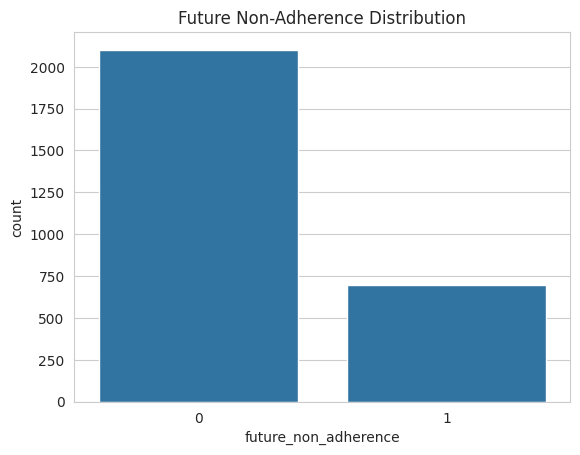

In [ ]:
sns.countplot(x='future_non_adherence', data=df)
plt.title('Future Non-Adherence Distribution')
plt.show()

Age Distribution

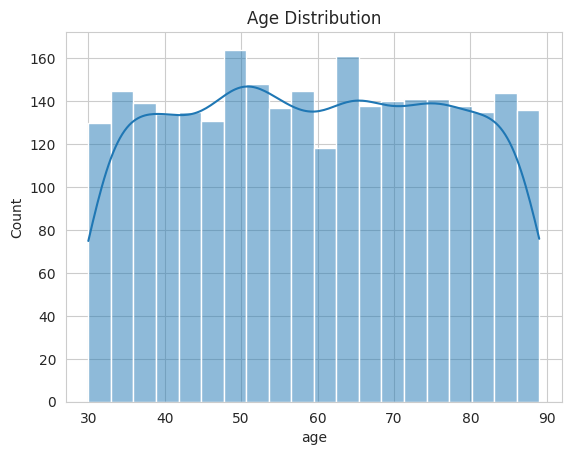

In [ ]:
sns.histplot(df['age'], kde=True, bins=20)
plt.title('Age Distribution')
plt.show()

Chronic Condition vs Adherence Risk

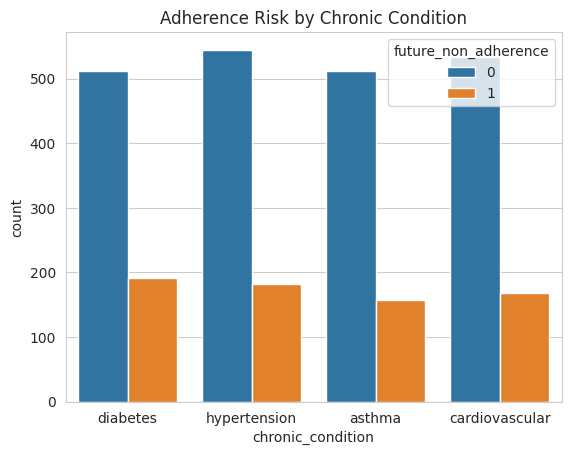

In [ ]:
sns.countplot(x='chronic_condition', hue='future_non_adherence', data=df)
plt.title('Adherence Risk by Chronic Condition')
plt.show()

Distribution of Numeric Health Features

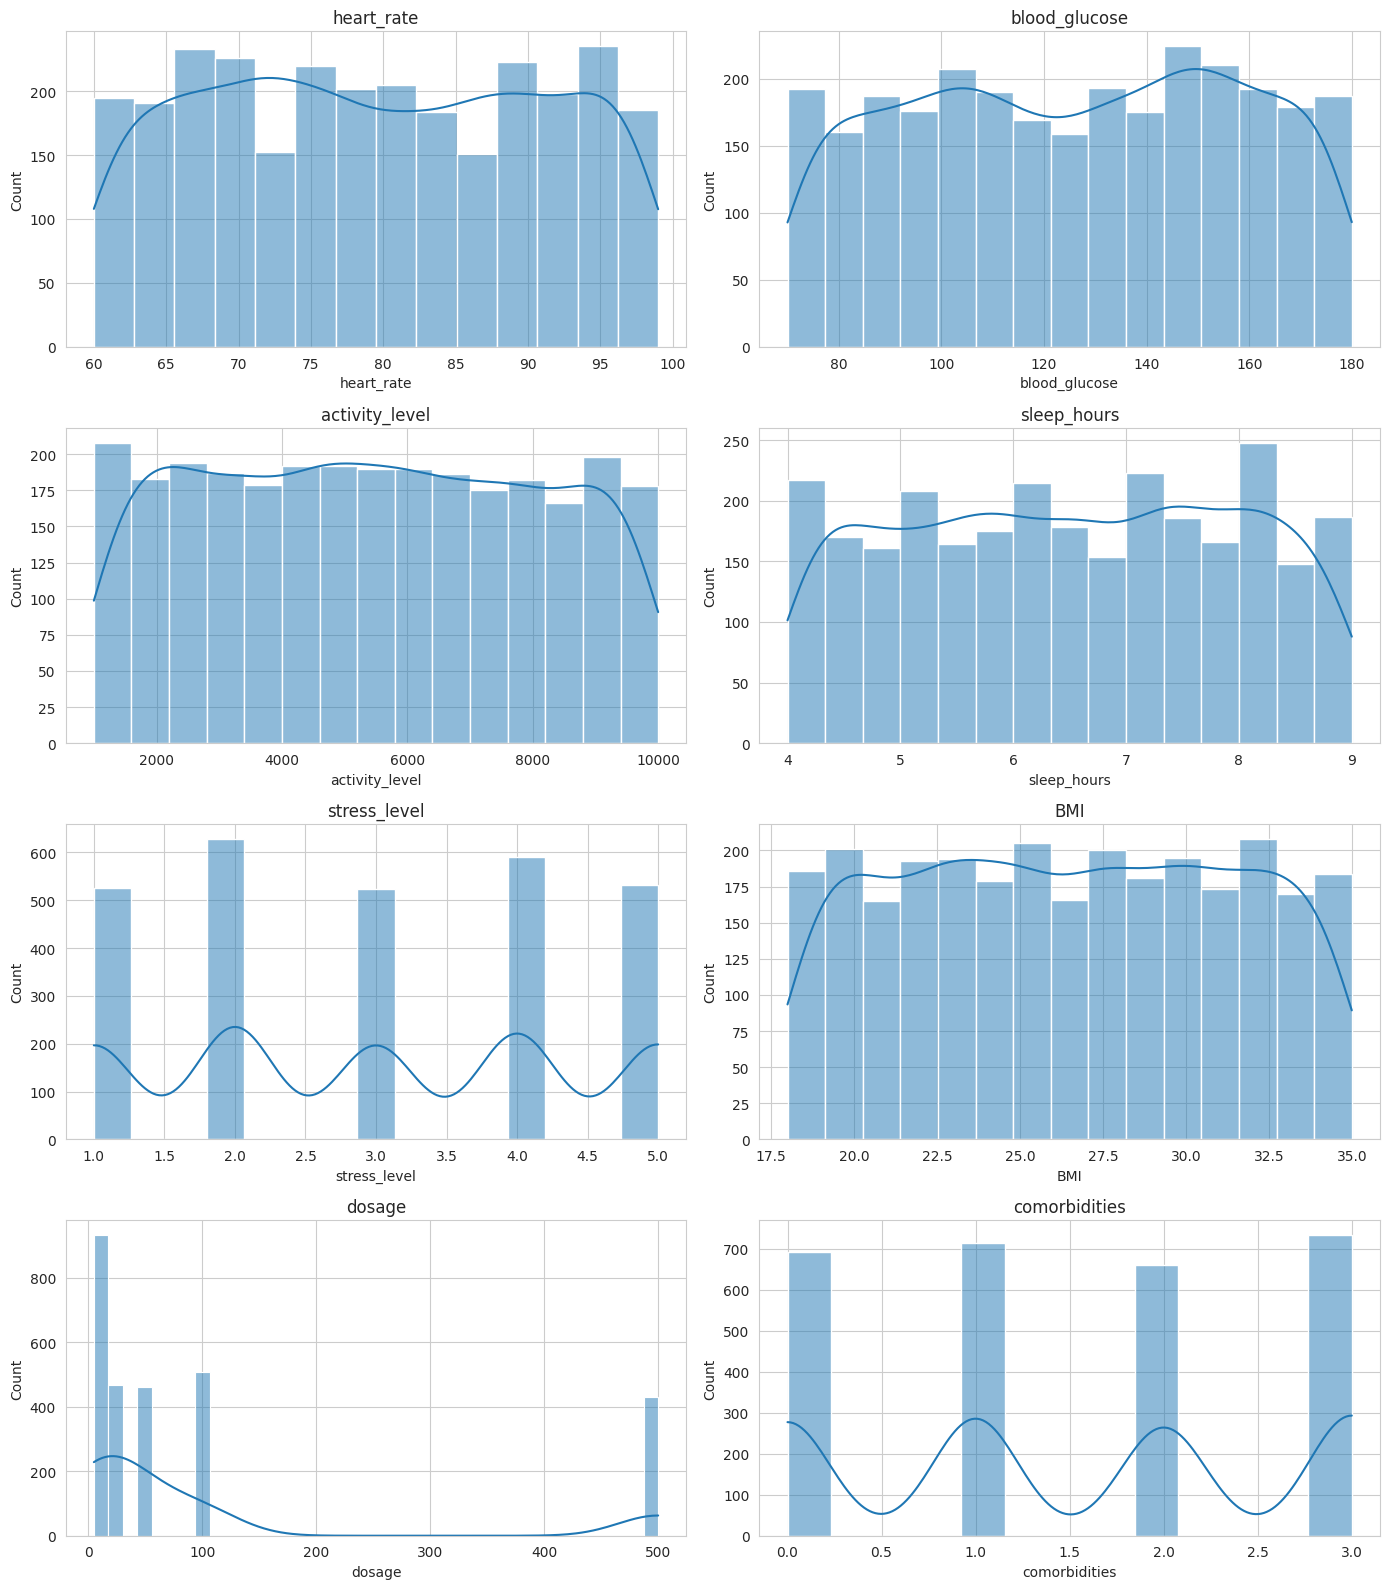

In [ ]:
numeric_cols = ['heart_rate', 'blood_glucose', 'activity_level', 'sleep_hours',
                 'stress_level', 'BMI', 'dosage', 'comorbidities']

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()
for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], kde=True, ax=axes[i])
    axes[i].set_title(col)
plt.tight_layout()
plt.show()

Stress & Sleep vs Adherence

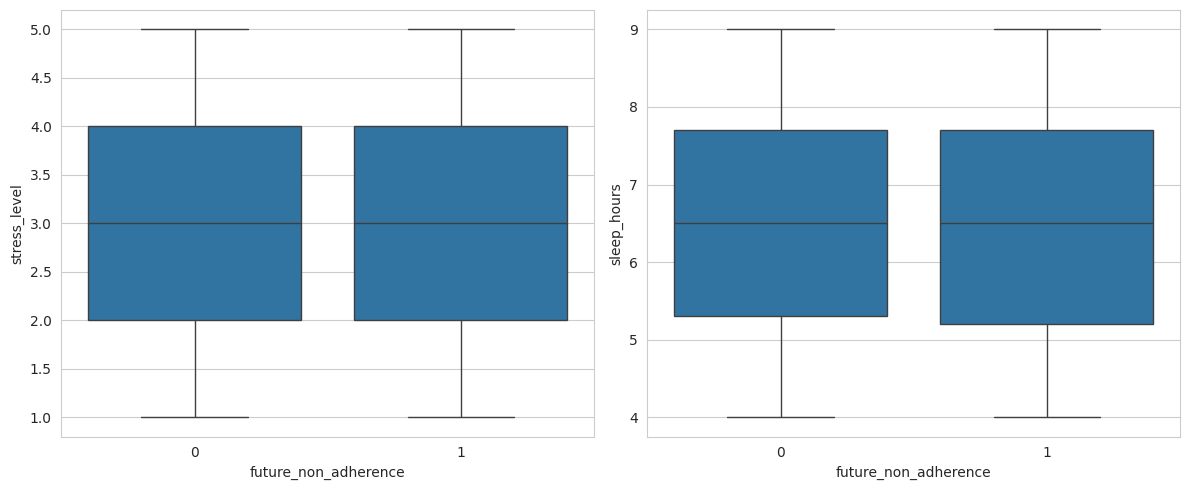

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))
sns.boxplot(x='future_non_adherence', y='stress_level', data=df, ax=axes[0])
sns.boxplot(x='future_non_adherence', y='sleep_hours', data=df, ax=axes[1])
plt.tight_layout()
plt.show()

Correlation Heatmap

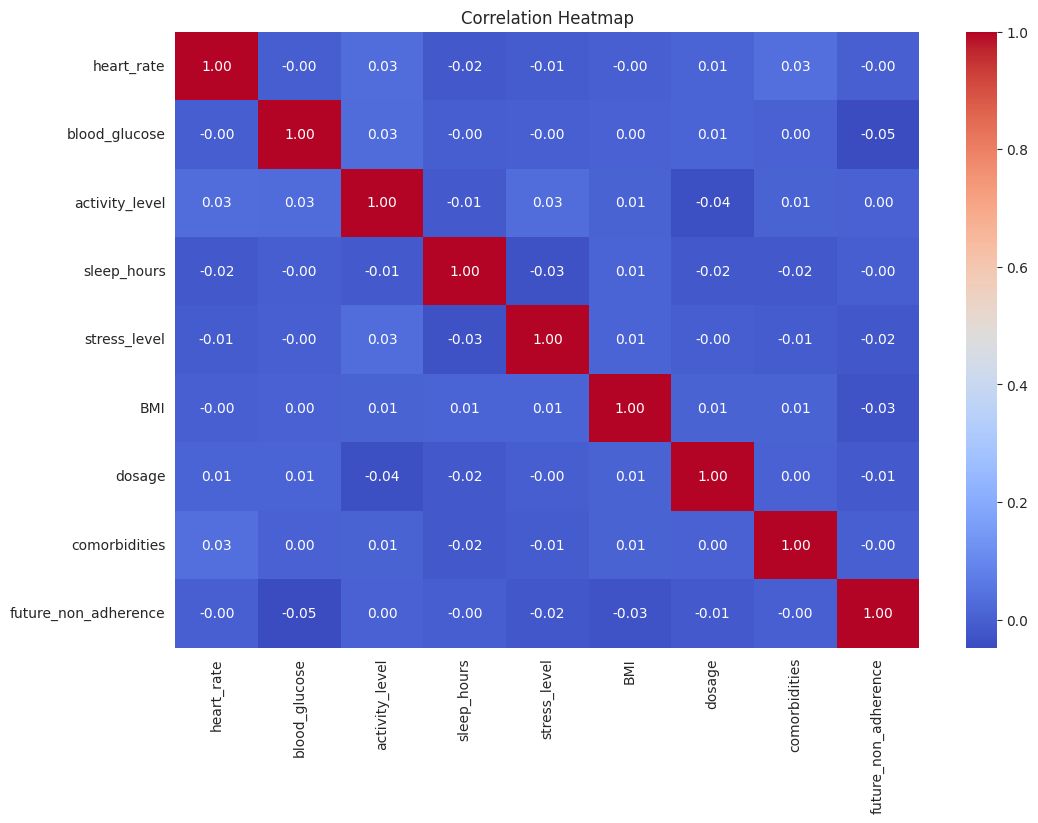

In [ ]:
plt.figure(figsize=(12,8))
sns.heatmap(df[numeric_cols + ['future_non_adherence']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

Reasons for Missed Medication

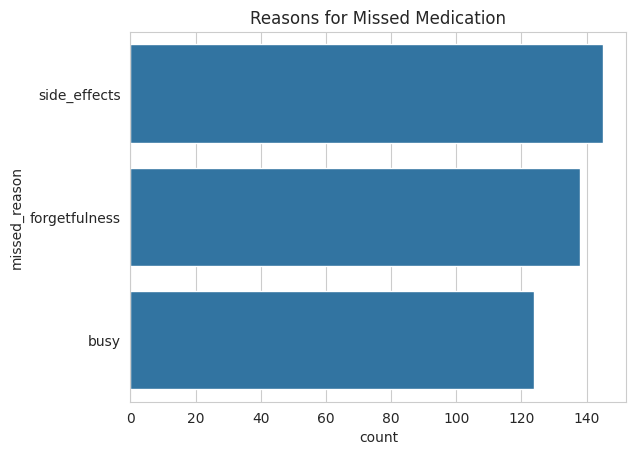

In [ ]:
sns.countplot(y='missed_reason', data=df, order=df['missed_reason'].value_counts().index)
plt.title('Reasons for Missed Medication')
plt.show()

Social Support & Location vs Adherence

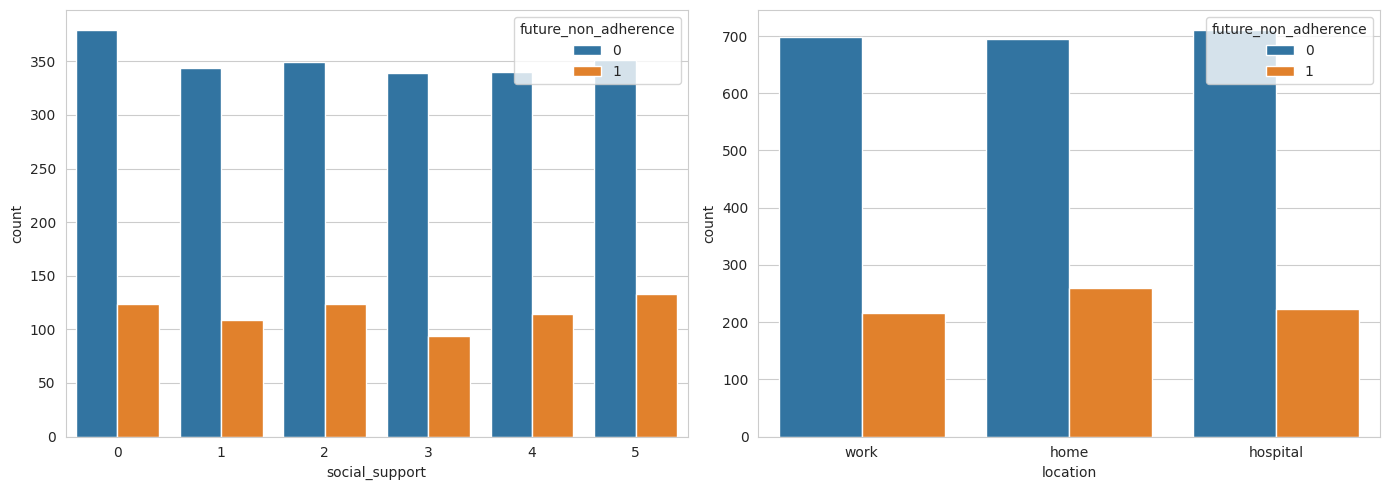

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.countplot(x='social_support', hue='future_non_adherence', data=df, ax=axes[0])
sns.countplot(x='location', hue='future_non_adherence', data=df, ax=axes[1])
plt.tight_layout()
plt.show()

Split Blood Pressure into Systolic & Diastolic

In [ ]:
df[['systolic_bp', 'diastolic_bp']] = df['blood_pressure'].str.split('/', expand=True).astype(int)
df.drop('blood_pressure', axis=1, inplace=True)

Handle Logical Missing Values

In [ ]:
df['missed_reason'] = df['missed_reason'].fillna('not_missed')
df['reminder_response_time'] = df['reminder_response_time'].fillna(0)

Extract Time-Based Features

In [ ]:
df['timestamp'] = pd.to_datetime(df['timestamp'])
df['hour'] = df['timestamp'].dt.hour
df['day_of_week'] = df['timestamp'].dt.dayofweek

Drop Identifier Columns

In [ ]:
df_model = df.drop(['patient_id', 'event_id', 'device_id', 'timestamp'], axis=1)

Encode Categorical Variables

In [ ]:
categorical_cols = ['gender', 'chronic_condition', 'medication_type', 'missed_reason', 'location']
df_encoded = pd.get_dummies(df_model, columns=categorical_cols, drop_first=True)

Feature-Target Split

In [ ]:
X = df_encoded.drop('future_non_adherence', axis=1)
y = df_encoded['future_non_adherence']

Scale Features & Train-Test Split

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

 Import ML Libraries

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix

Train & Evaluate Multiple Models

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(eval_metric='logloss', random_state=42)
}

results = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:,1]

    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC_AUC": roc_auc_score(y_test, y_prob)
    }
    print(f"\n--- {name} ---")
    print(classification_report(y_test, y_pred))

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_


--- Logistic Regression ---
              precision    recall  f1-score   support

           0       0.75      1.00      0.86       420
           1       0.00      0.00      0.00       140

    accuracy                           0.75       560
   macro avg       0.38      0.50      0.43       560
weighted avg       0.56      0.75      0.64       560



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_


--- Random Forest ---
              precision    recall  f1-score   support

           0       0.75      1.00      0.86       420
           1       0.00      0.00      0.00       140

    accuracy                           0.75       560
   macro avg       0.38      0.50      0.43       560
weighted avg       0.56      0.75      0.64       560


--- XGBoost ---
              precision    recall  f1-score   support

           0       0.74      0.92      0.82       420
           1       0.11      0.03      0.04       140

    accuracy                           0.70       560
   macro avg       0.42      0.47      0.43       560
weighted avg       0.58      0.70      0.63       560



Compare Model Performance

In [ ]:
results_df = pd.DataFrame(results).T
results_df

,Accuracy,Precision,Recall,F1,ROC_AUC
Logistic Regression,0.750000,0.000000,0.000000,0.000000,0.475425
Random Forest,0.750000,0.000000,0.000000,0.000000,0.431446
XGBoost,0.696429,0.105263,0.028571,0.044944,0.477500


Confusion Matrix Visualization

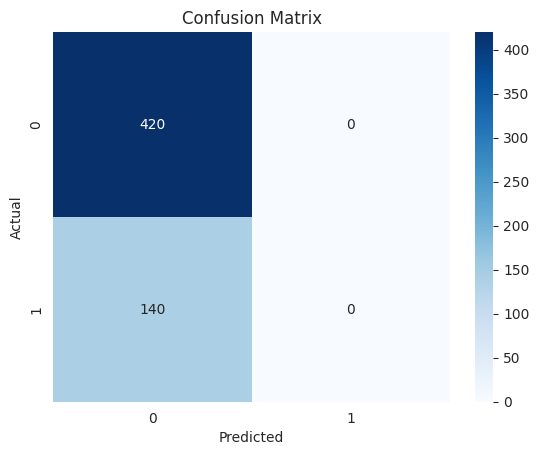

In [ ]:
best_model = models["Random Forest"]
y_pred = best_model.predict(X_test_scaled)

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

Feature Importance Analysis

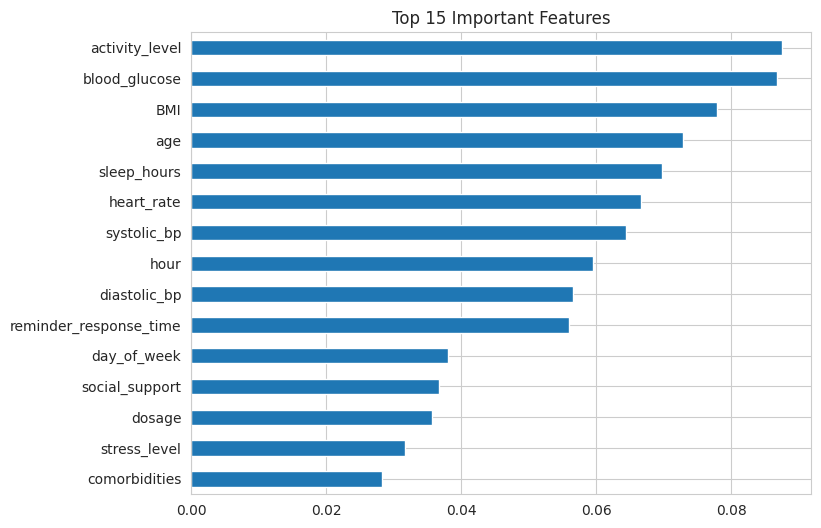

In [ ]:
importances = pd.Series(best_model.feature_importances_, index=X.columns)
importances.sort_values(ascending=False).head(15).plot(kind='barh', figsize=(8,6))
plt.title('Top 15 Important Features')
plt.gca().invert_yaxis()
plt.show()

In [ ]:
from transformers import pipeline

### Testing (selection of a patient and predict non-adherence risk)

In [ ]:
patient_index = X_test.index[0]

patient_data = df.loc[patient_index]

patient_features = X.loc[patient_index].to_frame().T
patient_features_scaled = scaler.transform(patient_features)

risk_probability = best_model.predict_proba(patient_features_scaled)[0][1]

if risk_probability >= 0.70:
    risk_level = "High"
elif risk_probability >= 0.40:
    risk_level = "Medium"
else:
    risk_level = "Low"

print("Predicted Non-Adherence Probability:",
      round(risk_probability * 100, 2), "%")
print("Risk Level:", risk_level)

Predicted Non-Adherence Probability: 28.0 %
Risk Level: Low


### Real Local LLM

In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

model_name = "google/flan-t5-small"

tokenizer = AutoTokenizer.from_pretrained(model_name)
llm_model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  308MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

In [ ]:
prompt = f"""
Give a short supportive medication adherence message.

Patient age: {patient_data['age']}
Chronic condition: {patient_data['chronic_condition']}
Stress level: {patient_data['stress_level']}
Sleep hours: {patient_data['sleep_hours']}
Activity level: {patient_data['activity_level']}
Medication type: {patient_data['medication_type']}
Predicted non-adherence risk: {risk_level}

Give one practical reminder and one motivational suggestion.
Do not diagnose or change medication.
"""

inputs = tokenizer(
    prompt,
    return_tensors="pt",
    truncation=True
)

outputs = llm_model.generate(
    **inputs,
    max_new_tokens=80,
    do_sample=True,
    temperature=0.7
)

personalised_message = tokenizer.decode(
    outputs[0],
    skip_special_tokens=True
)

print("\n------------- LLM PERSONALIZED SUPPORT -----------------")
print(personalised_message)


------------- LLM PERSONALIZED SUPPORT -----------------
Patient aged 42. Cardiac symptom: Cardion deficit: 4 Sleep hours: 7.3 Efforts to a non-adherence risk: Low


### Gamification

In [ ]:
medication_taken = True
current_streak = 7

points = 10 if medication_taken else 0

if current_streak >= 7:
    badge = "7-Day Adherence Champion"
    points += 25
elif current_streak >= 3:
    badge = "3-Day Adherence Streak"
    points += 10
else:
    badge = "Getting Started"

print("\n---------- GAMIFICATION ----------")
print("Medication Taken:", medication_taken)
print("Current Streak:", current_streak, "days")
print("Points Earned:", points)
print("Badge:", badge)

print("\n---------- FINAL OUTCOME ----------")
print("Risk Level:", risk_level)
print("Risk Probability:", round(risk_probability * 100, 2), "%")
print("LLM Message:", personalised_message)
print("Achievement:", badge)


---------- GAMIFICATION ----------
Medication Taken: True
Current Streak: 7 days
Points Earned: 35
Badge: 7-Day Adherence Champion

---------- FINAL OUTCOME ----------
Risk Level: Low
Risk Probability: 28.0 %
LLM Message: Patient aged 42. Cardiac symptom: Cardion deficit: 4 Sleep hours: 7.3 Efforts to a non-adherence risk: Low
Achievement: 7-Day Adherence Champion
